# SynthSeg — simulation of resolution variability (Sec. 3.1.4) step by step

Billot et al., *SynthSeg*, MedIA 86 (2023) 102789.

Goal: make the network robust to the acquisition **direction** (axial / coronal / sagittal),
**slice spacing** $r_{spac}$ and **slice thickness** $r_{thick}$. Starting from a high-resolution
image $I_{HR}$ (1 mm), we simulate a thick-slice scan and bring it back to 1 mm:

$$
\begin{aligned}
r_{spac} &\sim \mathcal{U}(r_{HR}, b_{res}) &(20)\\
r_{thick} &\sim \mathcal{U}(r_{HR}, r_{spac}) &(21)\\
\alpha &\sim \mathcal{U}(a_\alpha, b_\alpha) &(22)\\
\sigma_{thick} &= 2\alpha \log(10)(2\pi)^{-1}\, r_{thick}/r_{HR} &(23)\\
I_\sigma &= I_{HR} * \mathcal{N}(0, \sigma_{thick}) &(24)\\
I_{LR} &= \mathrm{Resample}(I_\sigma;\, r_{spac}) &(25)\\
I &= \mathrm{Resample}(I_{LR};\, r_{HR}) &(26)
\end{aligned}
$$

The label map is **not** degraded: the target $T$ stays at 1 mm (Sec. 3.1.5), so the CNN learns
to output crisp HR segmentations whatever the input resolution.

Plan of the notebook

1. Load $I_{HR}$ and the label map.
2. Sample the resolution parameters (eqs. 20–22).
3. Compute $\sigma_{thick}$ (eq. 23) and look at the kernel.
4. Blur along the slice direction (eq. 24).
5. Downsample to $r_{spac}$ (eq. 25).
6. Upsample back to $r_{HR}$ (eq. 26).
7. Wrap everything in a function, look at random samples, and see why the blur matters.
8. **Same thing with cornucopia** (`LowResSliceFinalTransform`), check it matches, and wrap it
   in a cornucopia random transform with SynthSeg's priors.
9. Segmentation target $T$ (Sec. 3.1.5).

In [1]:
import math

import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

import cornucopia as cc
from cornucopia.random import Uniform, RandInt
from cornucopia.base import NonFinalTransform

data_dir = "/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/augmentation/pipeline/data/inputs"
img_fpath = f"{data_dir}/T1w.nii.gz"
seg_fpath = f"{data_dir}/seg.nii.gz"

# fixed seed so the walkthrough is reproducible; remove it to get new samples
rng = np.random.default_rng(0)
torch.manual_seed(0)

## 1. Load the high-resolution image $I_{HR}$

In SynthSeg $I_{HR}$ is the image produced by the GMM + bias field steps (3.1.1–3.1.3).
Here we use a real 1 mm T1w so that the effect of the resolution simulation is easy to see;
the procedure is identical for a synthetic image.

Convention used everywhere below (same as cornucopia): tensors are `(C, X, Y, Z)`, and the
*slice axis* is a spatial axis `0, 1, 2`.

In [2]:
img_nii = nib.load(img_fpath)
seg_nii = nib.load(seg_fpath)

r_HR = float(img_nii.header.get_zooms()[0])          # 1 mm
print("shape:", img_nii.shape, "voxel size:", img_nii.header.get_zooms())

I_HR = img_nii.get_fdata().astype(np.float32)
I_HR = I_HR / np.percentile(I_HR, 99.9)               # roughly in [0, 1]
I_HR = np.clip(I_HR, 0, 1)
seg = seg_nii.get_fdata().astype(np.int64)

I_HR_t = torch.from_numpy(I_HR)[None]                 # (1, X, Y, Z)
print("I_HR tensor:", tuple(I_HR_t.shape))

shape: (197, 233, 189) voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
I_HR tensor: (1, 197, 233, 189)


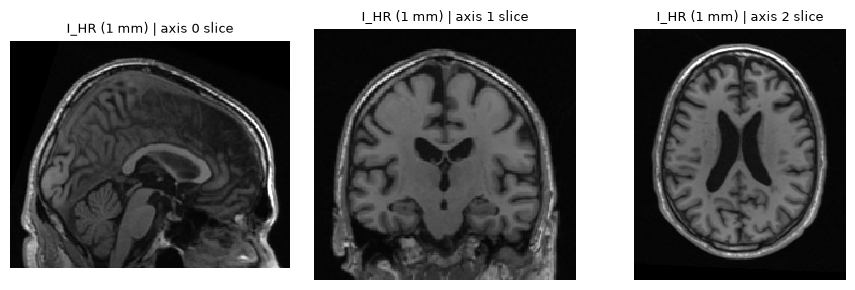

In [3]:
def show_views(vols, titles, slices=None, vmax=1, cmap="gray", figsize_per=3):
    '''One row per volume, 3 columns: sagittal (axis 0), coronal (axis 1), axial (axis 2).'''
    vols = [v.squeeze().numpy() if torch.is_tensor(v) else np.squeeze(v) for v in vols]
    if slices is None:
        slices = [s // 2 for s in vols[0].shape]
    fig, axes = plt.subplots(len(vols), 3, figsize=(3 * figsize_per, figsize_per * len(vols)), squeeze=False)
    for r, (v, t) in enumerate(zip(vols, titles)):
        cuts = [v[slices[0], :, :], v[:, slices[1], :], v[:, :, slices[2]]]
        for c, (cut, name) in enumerate(zip(cuts, ["axis 0", "axis 1", "axis 2"])):
            axes[r, c].imshow(np.rot90(cut), cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest")
            axes[r, c].set_title(f"{t} | {name} slice", fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.show()


show_views([I_HR], ["I_HR (1 mm)"])

## 2. Sample the resolution parameters (eqs. 20–22)

* **direction**: one of the 3 spatial axes, uniformly. Only that axis is degraded
  (thick-slice acquisition: in-plane stays at ~1 mm).
* $r_{spac} \sim \mathcal{U}(r_{HR}, b_{res})$: distance between slice centres.
* $r_{thick} \sim \mathcal{U}(r_{HR}, r_{spac})$: how much signal one slice integrates.
  Bounded by $r_{spac}$ because slices (almost) never overlap; $r_{thick} < r_{spac}$ means a gap.
* $\alpha \sim \mathcal{U}(a_\alpha, b_\alpha)$: small random deviation from the nominal thickness,
  which also softens the assumption that the slice profile is exactly Gaussian.

Hyper-parameters (SynthSeg Supplement 2 / public code): $b_{res} = 9$ mm, and the code uses
`blur_range = 1.03`, i.e. $\alpha \sim \mathcal{U}(1/1.03,\ 1.03)$.

In [33]:
b_res = 9.0                        # max slice spacing (mm)
a_alpha, b_alpha = 1 / 1.03, 1.03  # alpha range

axis    = int(rng.integers(3))                 # 0, 1 or 2
r_spac  = float(rng.uniform(r_HR, b_res))      # eq. 20
r_thick = float(rng.uniform(r_HR, r_spac))     # eq. 21
alpha   = float(rng.uniform(a_alpha, b_alpha)) # eq. 22

# for the walkthrough force a clearly visible case (comment out to keep the random draw)
axis, r_spac, r_thick = 2, 6.0, 4.0

print(f"axis={axis}  r_spac={r_spac:.2f} mm  r_thick={r_thick:.2f} mm  alpha={alpha:.3f}")

axis=2  r_spac=6.00 mm  r_thick=4.00 mm  alpha=0.987


## 3. Width of the slice-profile kernel (eq. 23)

A real slice is a (roughly) band-limited excitation profile. SynthSeg approximates it with a
Gaussian whose std $\sigma_{thick}$ is chosen so that the **power of the HR signal is divided
by 10 at the cut-off frequency** of the thick slice (Billot et al., 2020b):

$$\sigma_{thick} = \frac{2\alpha\log(10)}{2\pi}\,\frac{r_{thick}}{r_{HR}} \approx 0.733\,\alpha\,\frac{r_{thick}}{r_{HR}}\quad\text{(in HR voxels)}$$

(The public SynthSeg code uses the rounded constant `0.75 * res / atlas_res`.)

Below: the kernel compared with an ideal "box" slice of width $r_{thick}$.

sigma_thick = 2.892 voxels  (FWHM = 6.811 voxels)


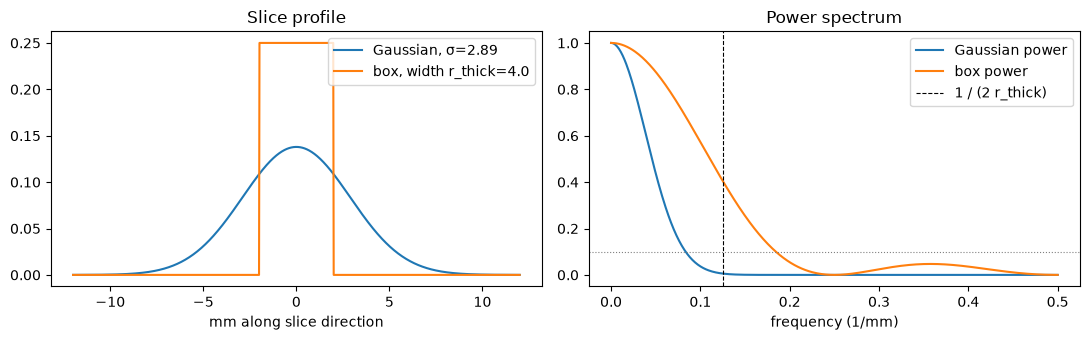

In [34]:
def sigma_thick_vox(r_thick, alpha, r_HR=1.0):
    '''eq. 23 -> std of the Gaussian slice profile, in HR voxels.'''
    return 2 * alpha * math.log(10) / (2 * math.pi) * r_thick / r_HR


sigma = sigma_thick_vox(r_thick, alpha, r_HR)
print(f"sigma_thick = {sigma:.3f} voxels  (FWHM = {sigma * 2 * math.sqrt(2 * math.log(2)):.3f} voxels)")

x = np.linspace(-3 * r_thick, 3 * r_thick, 1000)
gauss = np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
box = (np.abs(x) <= r_thick / 2) / r_thick

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(x, gauss, label=f"Gaussian, σ={sigma:.2f}")
ax[0].plot(x, box, label=f"box, width r_thick={r_thick:.1f}")
ax[0].set_xlabel("mm along slice direction"); ax[0].set_title("Slice profile"); ax[0].legend()

# frequency response (power): |FT|^2. cut-off of a slice of spacing r is f_c = 1 / (2 r)
f = np.linspace(0, 0.5, 500)
ax[1].plot(f, np.exp(-4 * np.pi**2 * sigma**2 * f**2), label="Gaussian power")
ax[1].plot(f, np.sinc(r_thick * f) ** 2, label="box power")
ax[1].axvline(1 / (2 * r_thick), ls="--", c="k", lw=0.8, label="1 / (2 r_thick)")
ax[1].axhline(0.1, ls=":", c="gray", lw=0.8)
ax[1].set_xlabel("frequency (1/mm)"); ax[1].set_title("Power spectrum"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Simulate slice thickness: blur along the slice axis (eq. 24)

$I_\sigma = I_{HR} * \mathcal{N}(0, \sigma_{thick})$, **only along the selected axis**
(the in-plane resolution is untouched). This is also the anti-aliasing filter for the
downsampling that follows.

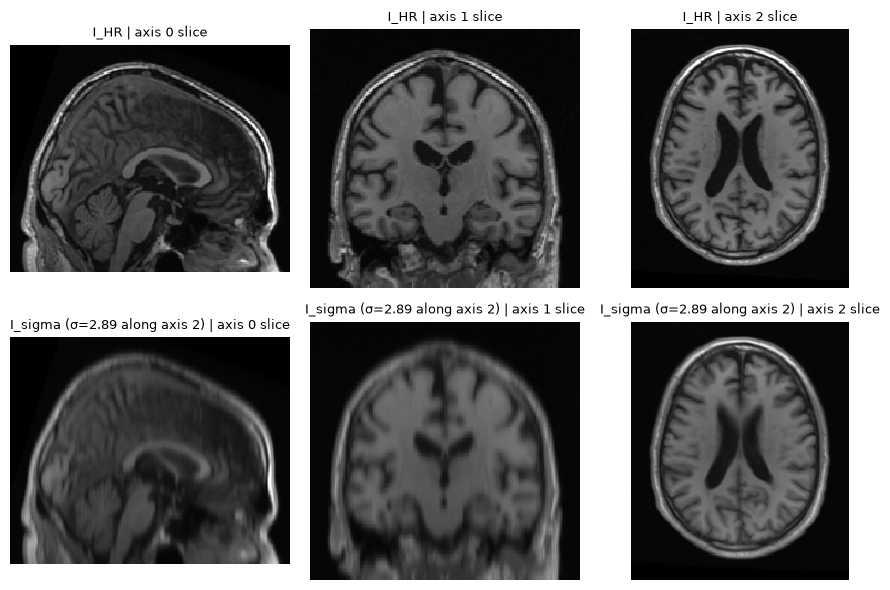

In [35]:
I_sigma = gaussian_filter1d(I_HR, sigma=sigma, axis=axis, mode="reflect")
show_views([I_HR, I_sigma], ["I_HR", f"I_sigma (σ={sigma:.2f} along axis {axis})"])

## 5. Simulate slice spacing: downsample to $r_{spac}$ (eq. 25)

Keep one sample every $r_{spac}$ mm along the slice axis using (tri)linear interpolation:
the number of slices becomes $\lceil n \cdot r_{HR} / r_{spac} \rceil$.

We use `align_corners=True` so that the first and last slices coincide with the HR ones
(this is also what cornucopia does, so both implementations can be compared exactly).

HR shape: (197, 233, 189) -> LR shape: (197, 233, 32)


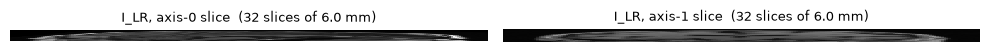

In [40]:
def lowres_shape(shape, axis, r_spac, r_HR=1.0):
    shape = list(shape)
    shape[axis] = max(2, math.ceil(shape[axis] * r_HR / r_spac))
    return shape


def resample(x, shape):
    '''Trilinear resampling of a (C, X, Y, Z) tensor to a new grid size.'''
    return F.interpolate(x[None], size=shape, mode="trilinear", align_corners=True)[0]


I_sigma_t = torch.from_numpy(I_sigma)[None]
lr_shape = lowres_shape(I_sigma_t.shape[1:], axis, r_spac, r_HR)
I_LR = resample(I_sigma_t, lr_shape)
print("HR shape:", tuple(I_HR_t.shape[1:]), "-> LR shape:", tuple(I_LR.shape[1:]))

# show the two in-slice-axis cuts with the correct physical aspect ratio
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
other = [a for a in range(3) if a != axis]
for k, a in enumerate(other):
    cut = I_LR[0].select(a, I_LR.shape[1 + a] // 2).numpy()     # 2D, contains the slice axis
    # after removing axis `a` the slice axis is at position (axis if axis < a else axis - 1)
    sa = axis if axis < a else axis - 1
    aspect = (r_spac / r_HR) if sa == 0 else (r_HR / r_spac)
    axes[k].imshow(np.rot90(cut), cmap="gray", vmin=0, vmax=1, aspect=aspect, interpolation="nearest")
    axes[k].set_title(f"I_LR, axis-{a} slice  ({lr_shape[axis]} slices of {r_spac:.1f} mm)", fontsize=9)
    axes[k].axis("off")
plt.tight_layout(); plt.show()

## 6. Upsample back to $r_{HR}$ (eq. 26)

The LR image is resampled (trilinear) back to the original 1 mm grid. The network always
sees inputs on the same 1 mm grid, while the label map $T$ stays crisp at 1 mm.

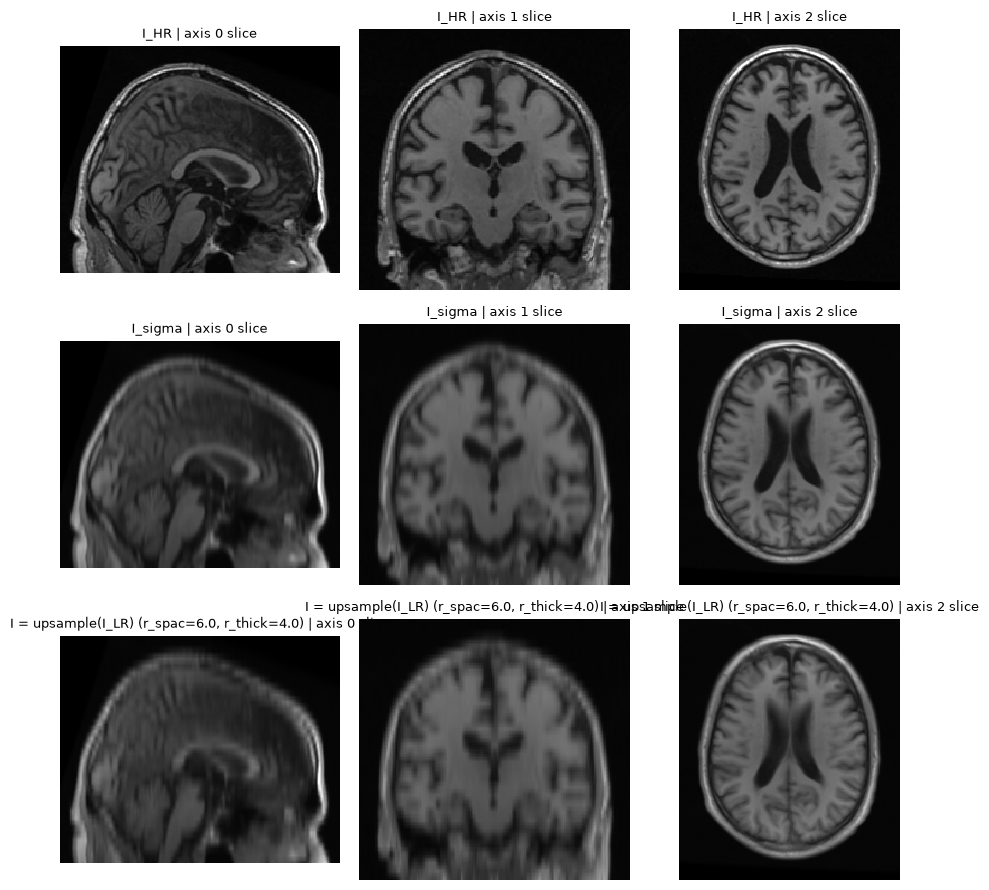

In [42]:
I_final = resample(I_LR, list(I_HR_t.shape[1:]))
show_views([I_HR, I_sigma, I_final],
           ["I_HR", "I_sigma", f"I = upsample(I_LR) (r_spac={r_spac:.1f}, r_thick={r_thick:.1f})"])

## 7. Everything in one function + random samples

Putting eqs. 20–26 together.

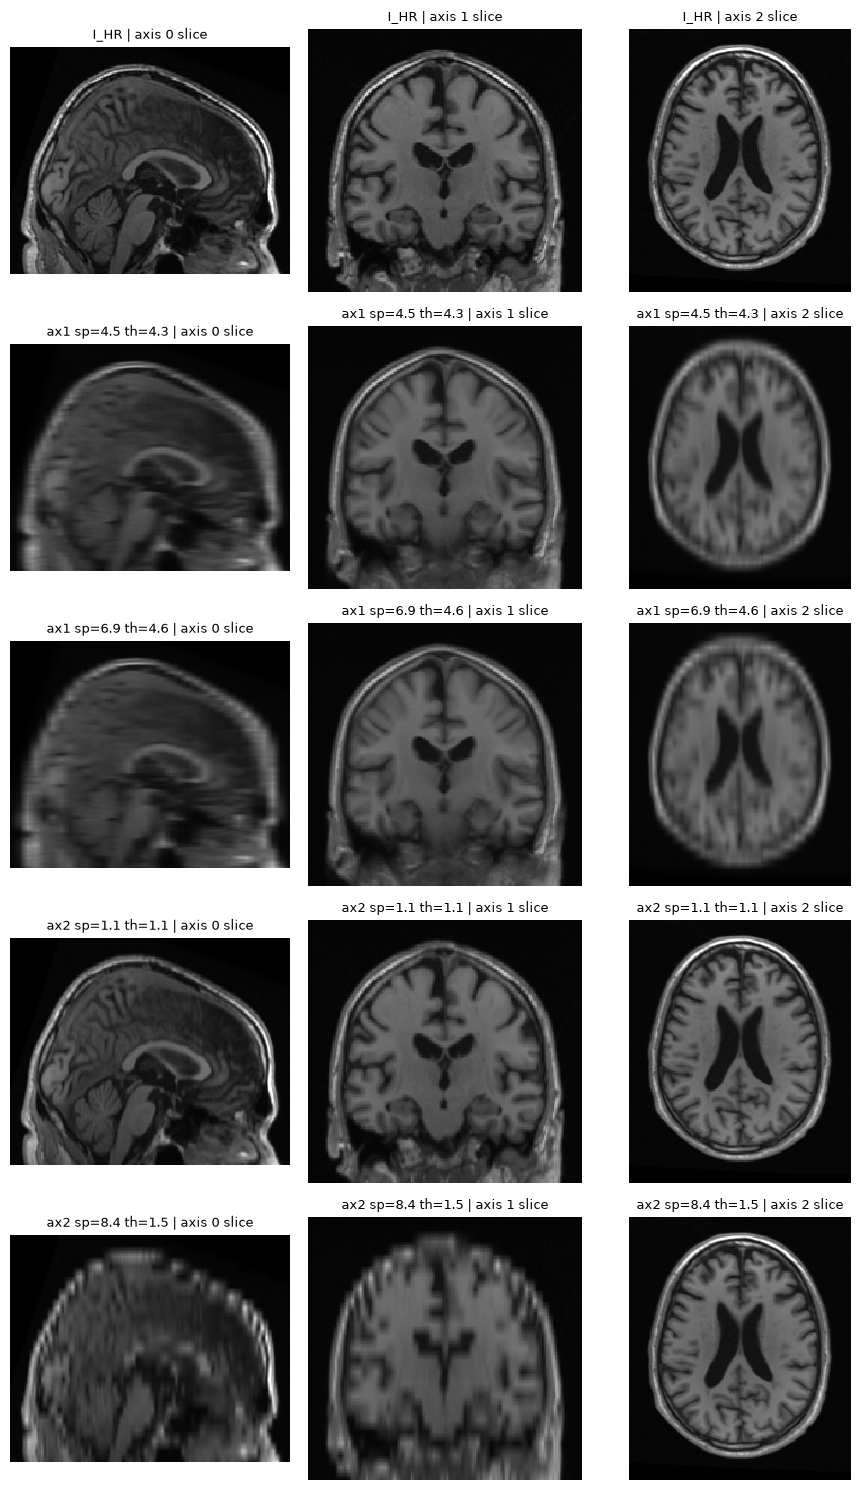

In [43]:
def synthseg_resolution(I_HR, rng, r_HR=1.0, b_res=9.0, alpha_range=(1 / 1.03, 1.03),
                        axis=None, r_spac=None, r_thick=None, blur=True):
    '''
    SynthSeg Sec. 3.1.4. I_HR: (C, X, Y, Z) torch tensor at r_HR.
    Any of axis / r_spac / r_thick can be fixed, otherwise they are sampled.
    Returns the final 1 mm image and the sampled parameters.
    '''
    if axis is None:
        axis = int(rng.integers(3))
    if r_spac is None:
        r_spac = float(rng.uniform(r_HR, b_res))                 # eq. 20
    if r_thick is None:
        r_thick = float(rng.uniform(r_HR, r_spac))               # eq. 21
    alpha = float(rng.uniform(*alpha_range))                     # eq. 22
    sigma = sigma_thick_vox(r_thick, alpha, r_HR)                # eq. 23

    x = I_HR
    if blur:                                                     # eq. 24
        x = torch.from_numpy(gaussian_filter1d(x.numpy(), sigma=sigma, axis=axis + 1, mode="reflect"))
    x_lr = resample(x, lowres_shape(x.shape[1:], axis, r_spac, r_HR))   # eq. 25
    x_hr = resample(x_lr, list(I_HR.shape[1:]))                         # eq. 26
    prm = dict(axis=axis, r_spac=r_spac, r_thick=r_thick, alpha=alpha, sigma=sigma)
    return x_hr, x_lr, prm


samples, titles = [I_HR_t], ["I_HR"]
for _ in range(4):
    out, _, p = synthseg_resolution(I_HR_t, rng)
    samples.append(out)
    titles.append(f"ax{p['axis']} sp={p['r_spac']:.1f} th={p['r_thick']:.1f}")
show_views(samples, titles)

### Why the blur (eq. 24) matters

Without the slice-profile blur, downsampling just *picks* slices: high frequencies alias into
the LR image and you get a jagged, staircase look that does not resemble a real thick-slice scan.
With the blur, each LR slice is a weighted average over its thickness (partial volume),
as in a real acquisition.

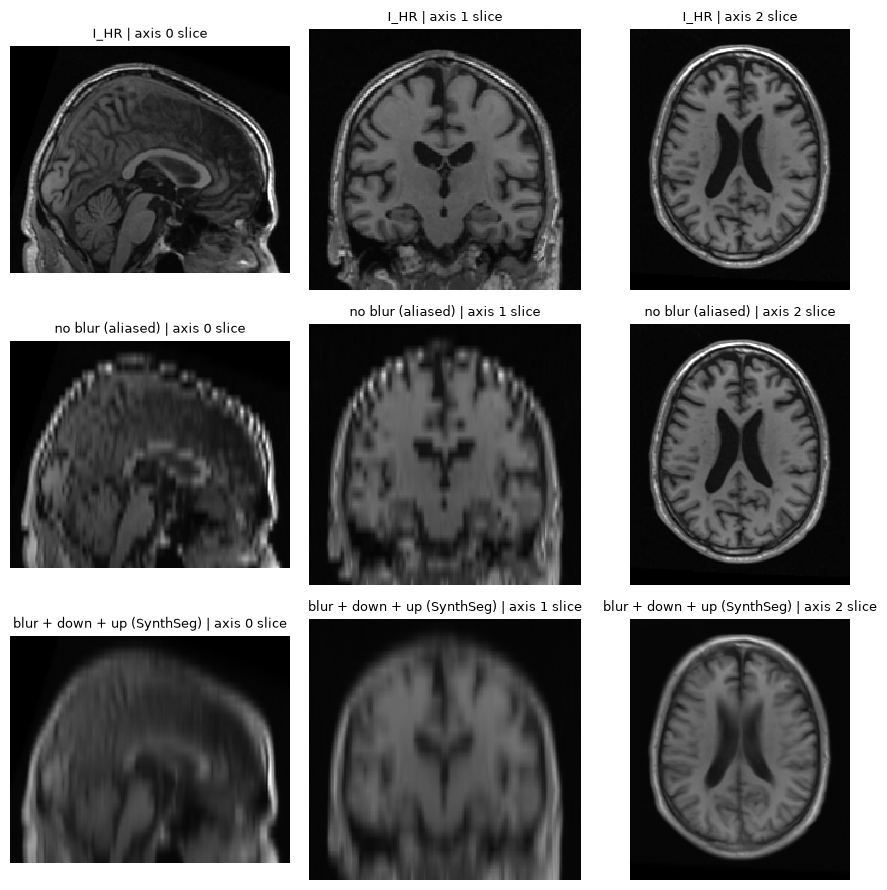

In [44]:
fixed = dict(axis=2, r_spac=7.0, r_thick=7.0)
no_blur, _, _ = synthseg_resolution(I_HR_t, np.random.default_rng(1), blur=False, **fixed)
with_blur, _, _ = synthseg_resolution(I_HR_t, np.random.default_rng(1), blur=True, **fixed)
show_views([I_HR_t, no_blur, with_blur], ["I_HR", "no blur (aliased)", "blur + down + up (SynthSeg)"])

## 8. The same with cornucopia

cornucopia implements exactly this blur → downsample → (noise) → upsample chain in
`cc.LowResSliceFinalTransform(axis, resolution, thickness)` (file `cornucopia/psf.py`):

```python
fwhm[axis] = resolution * thickness     # 1. smooth (Gaussian, FWHM in voxels)
y = smoothnd(x, fwhm=fwhm)
y = interpolate(y, oshape, align_corners=True, mode='trilinear')   # 2. downsample
y = noise(y)                                                       # 3. optional, in LR space
z = interpolate(y, ishape, align_corners=True, mode='trilinear')   # 4. upsample back
```

with `oshape[axis] = ceil(n / resolution)`. Its parameterisation is different from SynthSeg:

| cornucopia | meaning | SynthSeg equivalent |
|---|---|---|
| `resolution` | slice spacing in HR voxels | $r_{spac}/r_{HR}$ |
| `thickness` | FWHM of the slice Gaussian **as a fraction of `resolution`** | $\mathrm{FWHM}(\sigma_{thick}) / (r_{spac}/r_{HR})$ |

with $\mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma \approx 2.355\,\sigma$. So the mapping is

$$\texttt{thickness} = \frac{2\sqrt{2\ln2}\;\sigma_{thick}}{r_{spac}/r_{HR}}$$

Note: with SynthSeg's $\sigma_{thick}$ this value can be > 1 (e.g. $r_{thick}=r_{spac}$ gives
$\approx 1.73$), which `LowResSliceFinalTransform` accepts without problems.

### 8.1 Deterministic: reproduce the manual result

cornucopia: axis=2 resolution=6.000 thickness=1.135 -> fwhm=6.811 vox
LR shape manual: (197, 233, 32) | cornucopia: (197, 233, 32)
|cornucopia - manual|: max=0.0036  mean=0.00012


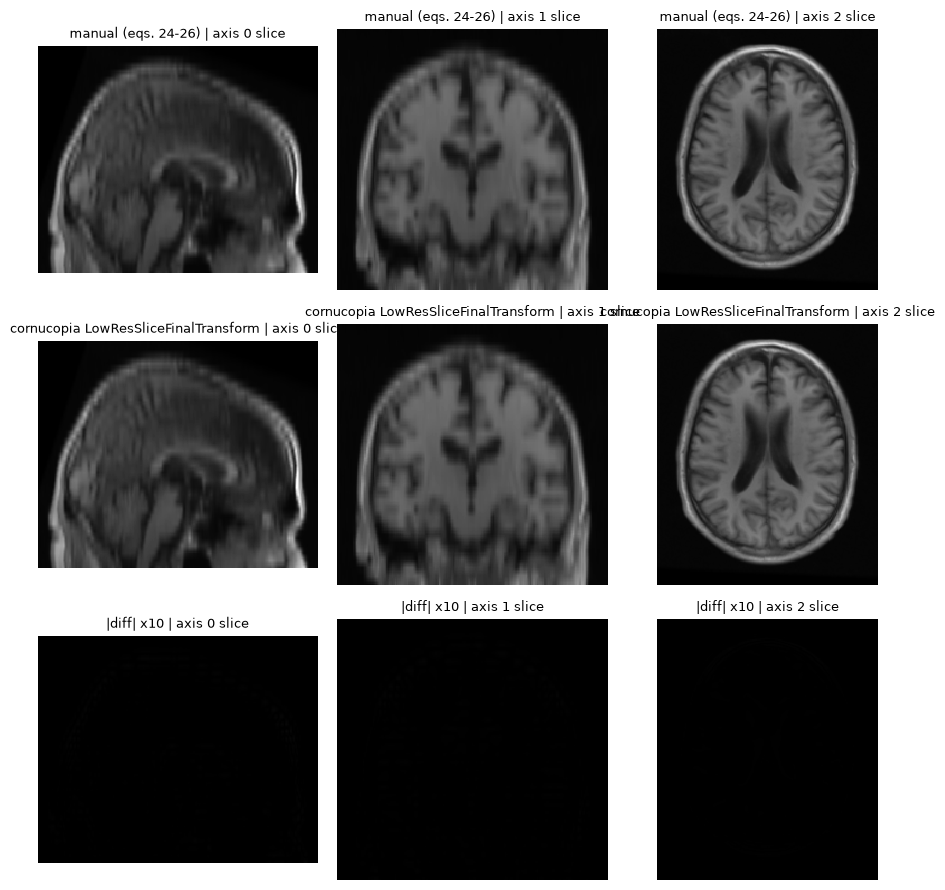

In [45]:
FWHM_PER_SIGMA = 2 * math.sqrt(2 * math.log(2))


def synthseg_to_cornucopia(r_spac, sigma, r_HR=1.0):
    '''SynthSeg (r_spac in mm, sigma in HR voxels) -> cornucopia (resolution, thickness).'''
    resolution = r_spac / r_HR
    thickness = FWHM_PER_SIGMA * sigma / resolution
    return resolution, thickness


resolution, thickness = synthseg_to_cornucopia(r_spac, sigma, r_HR)
print(f"cornucopia: axis={axis} resolution={resolution:.3f} thickness={thickness:.3f} "
      f"-> fwhm={resolution * thickness:.3f} vox")

xform = cc.LowResSliceFinalTransform(axis=axis, resolution=resolution, thickness=thickness,
                                     returns=dict(lowres="lowres", output="output"))
out_cc = xform(I_HR_t)
I_cc, I_LR_cc = out_cc["output"], out_cc["lowres"]
print("LR shape manual:", tuple(I_LR.shape[1:]), "| cornucopia:", tuple(I_LR_cc.shape[1:]))

diff = (I_cc - I_final).abs()
print(f"|cornucopia - manual|: max={diff.max():.4f}  mean={diff.mean():.5f}")

show_views([I_final, I_cc, diff * 10],
           ["manual (eqs. 24-26)", "cornucopia LowResSliceFinalTransform", "|diff| x10"])

The two results are almost identical. The small residual comes from the smoothing kernel:
cornucopia's `smoothnd` uses a Gaussian convolved with a linear (triangle) B-spline basis
(`basis=1`, so that the discrete kernel integrates exactly to one), whereas
`scipy.ndimage.gaussian_filter1d` samples a pure Gaussian; boundary handling also differs
(`dct2` vs `reflect`). Both are equally valid approximations of eq. 24.

### 8.2 Random: SynthSeg priors as a cornucopia transform

cornucopia already has `cc.RandomLowResSliceTransform`, but with its own priors:
`resolution ~ U(1, max)` (ok, like eq. 20) and `thickness ~ U(t, 1)` as a *fraction of the
spacing* — i.e. FWHM ≤ spacing, which blurs less than SynthSeg and has no $\alpha$.

To get exactly SynthSeg's priors (eqs. 20–23) while staying in the cornucopia ecosystem
(composable with `cc.SequentialTransform`, `returns=`, `shared=`, …), we write a tiny
`NonFinalTransform` whose `_unroll` samples the parameters and returns a
`LowResSliceFinalTransform`. This is the same pattern cornucopia uses internally.

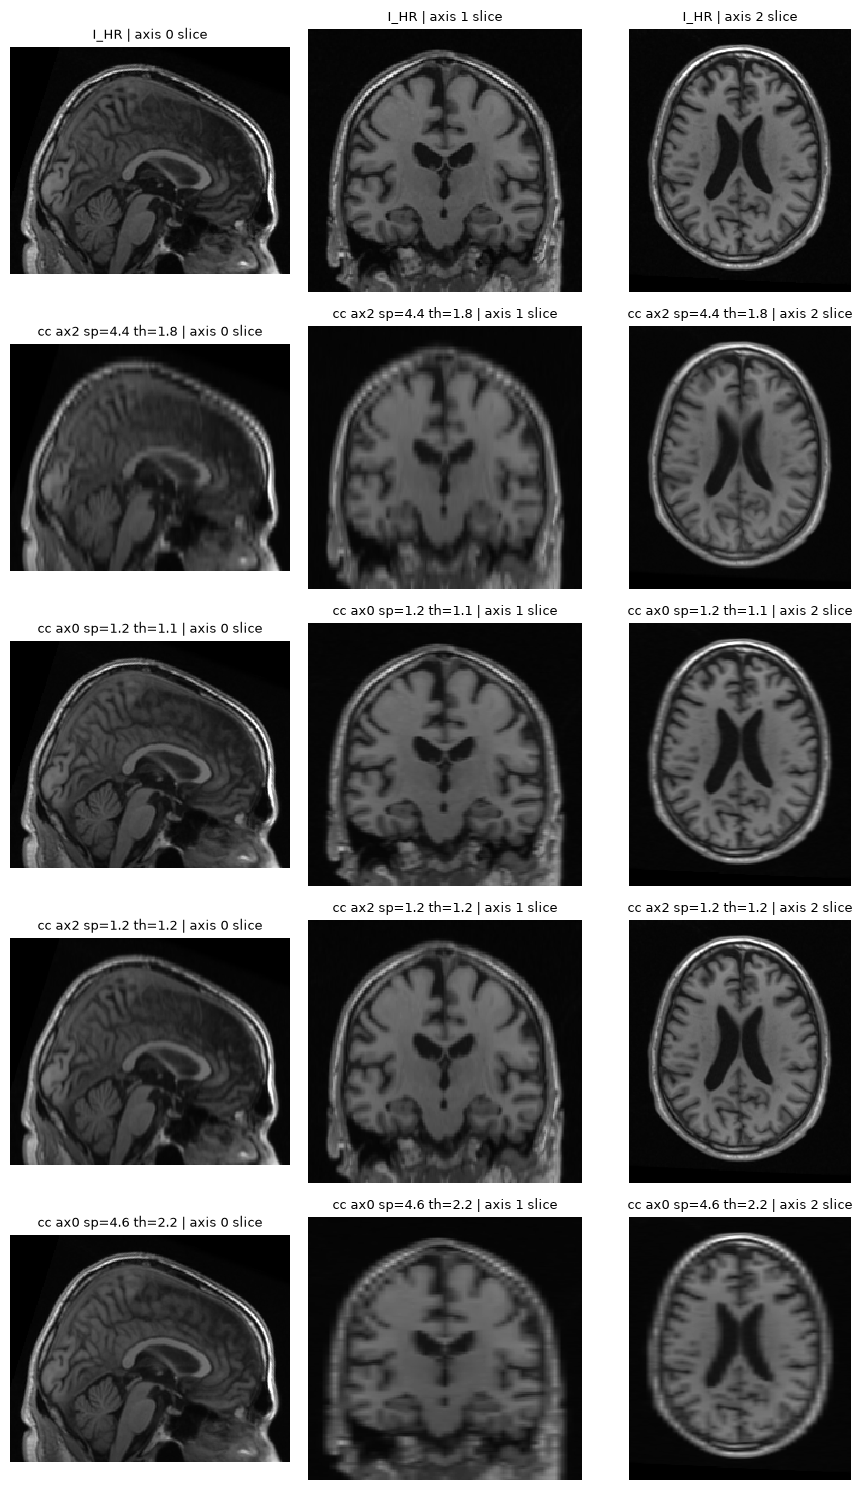

(1, 197, 233, 189)


In [46]:
class SynthSegLowResTransform(NonFinalTransform):
    '''
    SynthSeg resolution augmentation (Billot et al. 2023, Sec. 3.1.4, eqs. 20-26)
    implemented on top of cornucopia's LowResSliceFinalTransform.
    '''

    def __init__(self, r_HR=1.0, b_res=9.0, alpha=(1 / 1.03, 1.03), axis=None, noise=None, **kwargs):
        super().__init__(**kwargs)
        self.r_HR = r_HR
        self.b_res = b_res
        self.alpha = alpha
        self.axis = axis
        self.noise = noise

    def _unroll(self, x, max_depth=math.inf):
        if max_depth == 0:
            return self
        axis = RandInt(x.ndim - 2)() if self.axis is None else self.axis
        r_spac = Uniform(self.r_HR, self.b_res)()                     # eq. 20
        r_thick = Uniform(self.r_HR, r_spac)()                        # eq. 21
        alpha = Uniform(*self.alpha)()                                # eq. 22
        sigma = sigma_thick_vox(r_thick, alpha, self.r_HR)            # eq. 23
        resolution, thickness = synthseg_to_cornucopia(r_spac, sigma, self.r_HR)
        final = cc.LowResSliceFinalTransform(axis, resolution, thickness, self.noise, **self.get_prm())
        final = final.unroll(x, max_depth - 1)   # (also unrolls `noise`, if any)
        # keep the sampled values around for inspection
        final.synthseg_prm = dict(axis=axis, r_spac=r_spac, r_thick=r_thick, alpha=alpha, sigma=sigma)
        return final


synth_lowres = SynthSegLowResTransform()

samples, titles = [I_HR_t], ["I_HR"]
for _ in range(4):
    final = synth_lowres.unroll(I_HR_t)       # sample parameters once ...
    samples.append(final(I_HR_t))             # ... and apply them
    p = final.synthseg_prm
    titles.append(f"cc ax{p['axis']} sp={p['r_spac']:.1f} th={p['r_thick']:.1f}")
show_views(samples, titles)

# in a pipeline you would simply call it: a new random draw at every call
print(tuple(synth_lowres(I_HR_t).shape))

For comparison, cornucopia's built-in random transform (its own priors, see above):

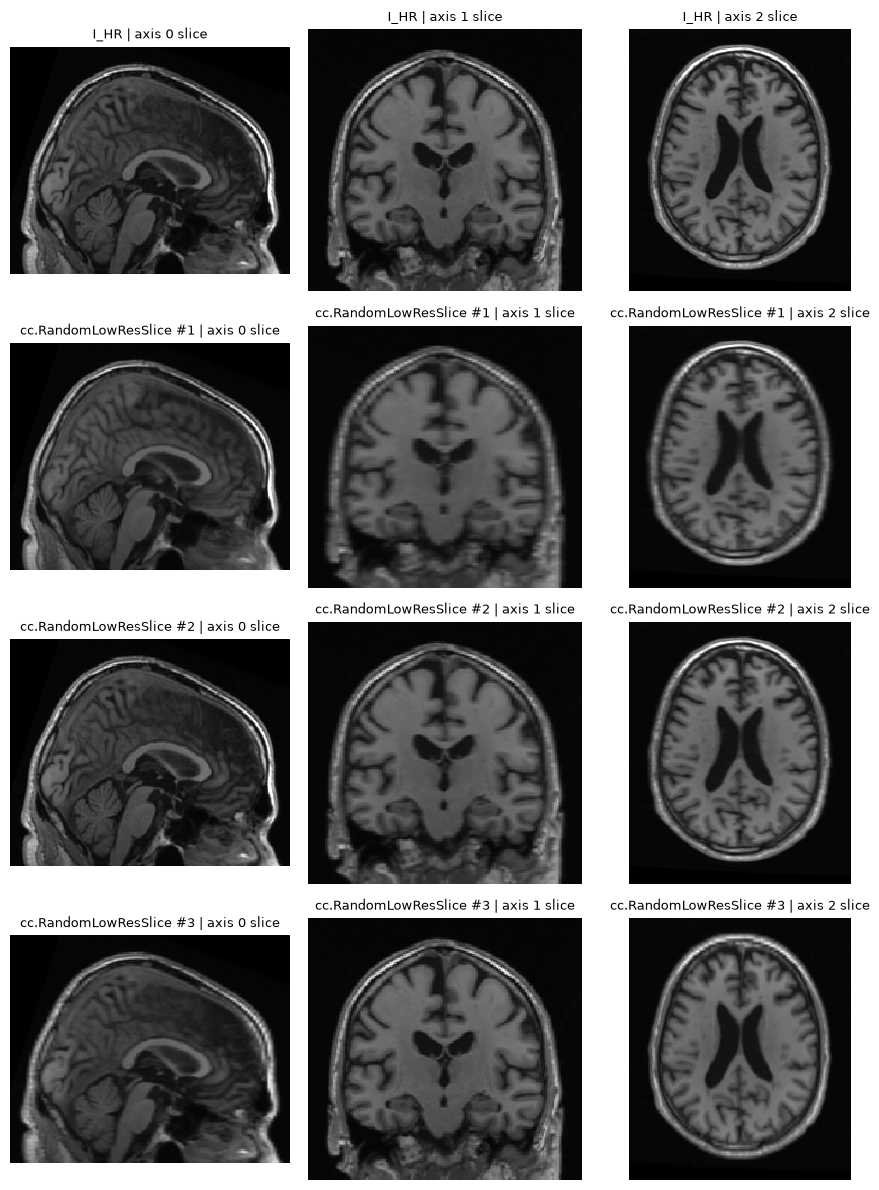

In [47]:
builtin = cc.RandomLowResSliceTransform(resolution=b_res / r_HR, thickness=0.1)
show_views([I_HR_t] + [builtin(I_HR_t) for _ in range(3)],
           ["I_HR", "cc.RandomLowResSlice #1", "cc.RandomLowResSlice #2", "cc.RandomLowResSlice #3"])

### 8.3 Noise in low-resolution space (optional)

`LowResSliceFinalTransform` accepts a `noise` transform that is applied to $I_{LR}$
**before** upsampling. In a real scan noise is i.i.d. at the acquired resolution, so after
upsampling it becomes correlated along the slice axis. (SynthSeg itself adds its noise
earlier, in the HR image, Sec. 3.1.3; this is an optional refinement.)

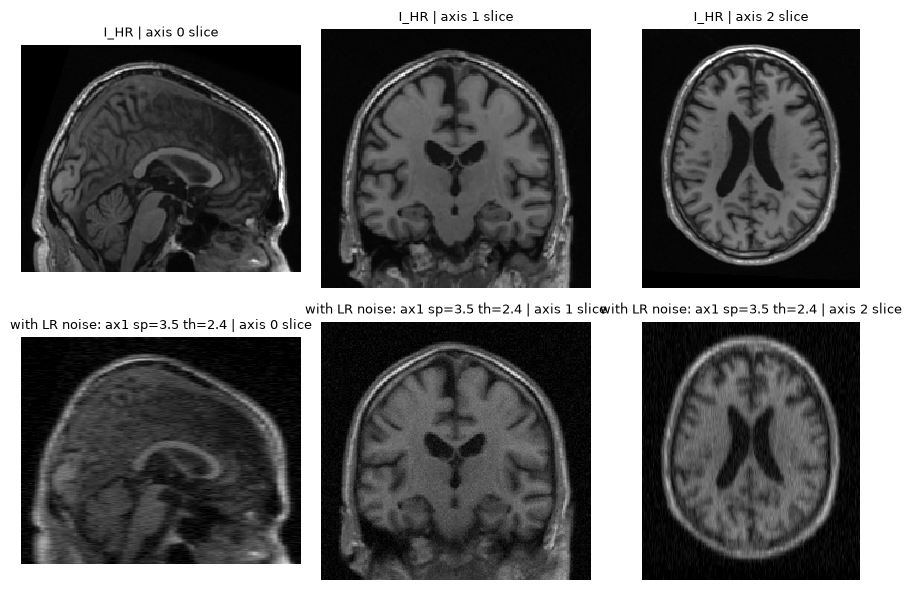

In [48]:
noisy = SynthSegLowResTransform(noise=cc.GaussianNoiseTransform(sigma=0.03))
final = noisy.unroll(I_HR_t)
p = final.synthseg_prm
show_views([I_HR_t, final(I_HR_t)],
           ["I_HR", f"with LR noise: ax{p['axis']} sp={p['r_spac']:.1f} th={p['r_thick']:.1f}"])

## 9. Model output and segmentation target (Sec. 3.1.5)

Each training step produces two volumes:

* the image $I$ (GMM → bias → noise → **resolution simulation**, all of the above);
* the target $T$: the *deformed* label map $L$ (eq. 10), with all labels we do not want
  to segment reset to background, so $T$ has $K' \le K$ labels.

The key point for this notebook: the resolution simulation is applied to **the image only**.
$T$ stays on the 1 mm grid with sharp boundaries, so the network learns LR image → HR labels.

Here, as an example, cortical parcels (1000s / 2000s) are merged into left / right cortex
(3 / 42) and any label outside SynthSeg's list of segmented structures is set to 0.

labels in L: 99 | labels in T (K'): 33
{'axis': 1, 'r_spac': 4.264008115103178, 'r_thick': 1.530667562164504, 'alpha': 0.9946549704433568, 'sigma': 1.1158842606120296}


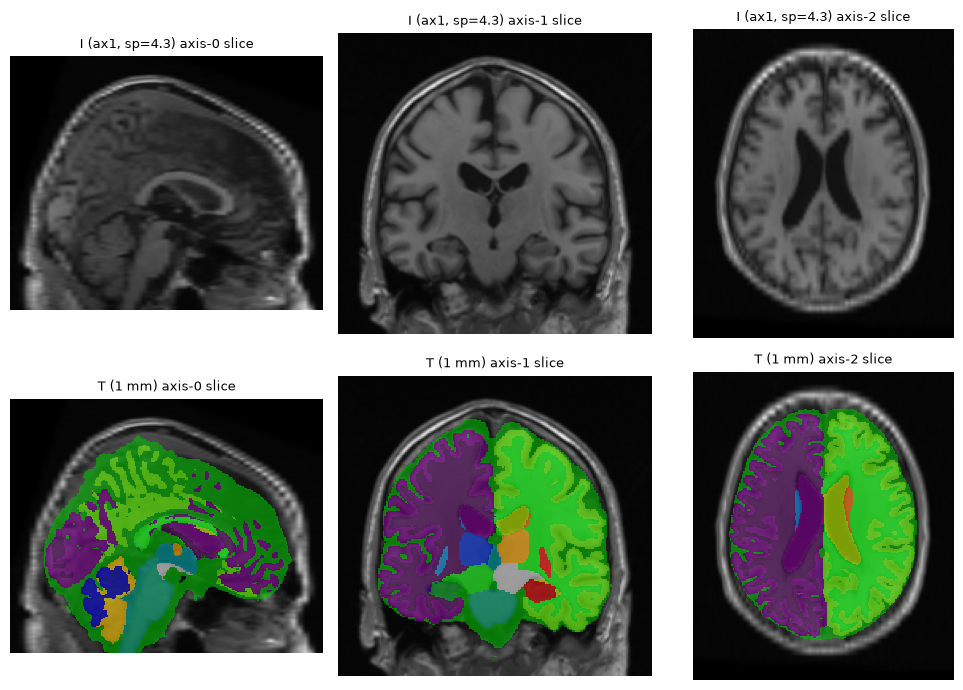

In [49]:
# SynthSeg 1.0 segmented labels (FreeSurfer aseg convention)
segmentation_labels = [0, 2, 3, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 24, 26, 28,
                       41, 42, 43, 44, 46, 47, 49, 50, 51, 52, 53, 54, 58, 60]

L = seg.copy()
L[(L >= 1000) & (L < 2000)] = 3      # left cortical parcels  -> left cortex
L[(L >= 2000) & (L < 3000)] = 42     # right cortical parcels -> right cortex
T = np.where(np.isin(L, segmentation_labels), L, 0)
print("labels in L:", len(np.unique(seg)), "| labels in T (K'):", len(np.unique(T)))

# final training pair: degraded image + crisp HR target
# (re-draw until the sample is clearly low-res, just so the figure is informative)
final = synth_lowres.unroll(I_HR_t)
while final.synthseg_prm["r_spac"] < 4:
    final = synth_lowres.unroll(I_HR_t)
I = final(I_HR_t)
p = final.synthseg_prm
print(p)

# relabel to 0..K'-1 so that the colormap is readable; background transparent
_, T_idx = np.unique(T, return_inverse=True)
T_show = np.ma.masked_equal(T_idx.reshape(T.shape), 0)

sl = [s // 2 for s in T.shape]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for c, a in enumerate(range(3)):
    axes[0, c].imshow(np.rot90(I[0].select(a, sl[a]).numpy()), cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"I (ax{p['axis']}, sp={p['r_spac']:.1f}) axis-{a} slice", fontsize=9)
    axes[1, c].imshow(np.rot90(I[0].select(a, sl[a]).numpy()), cmap="gray", vmin=0, vmax=1)
    axes[1, c].imshow(np.rot90(np.take(T_show, sl[a], axis=a)), cmap="nipy_spectral",
                      vmin=0, vmax=T_idx.max(), alpha=0.6, interpolation="nearest")
    axes[1, c].set_title(f"T (1 mm) axis-{a} slice", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()